# 🏡 Pre-entrega: Construcción de un Pipeline de Preprocesamiento Robusto
**Curso:** Data Science II - Coderhouse  
**Nivel:** Estudiante Inicial de Data Science  
**Dataset:** Ames Housing (House Prices)  

---

## 🎯 Objetivo de la Práctica
El objetivo de esta práctica es consolidar habilidades en la automatización de la limpieza y transformación de datos utilizando **Scikit-Learn Pipelines** y **ColumnTransformer**.

En lugar de aplicar transformaciones manuales y dispersas que puedan generar inconsistencias o **fuga de datos (data leakage)**, construiremos una arquitectura modular, reutilizable y profesional que reciba datos crudos y genere predicciones precisas de forma confiable.

### 📋 Criterios a Cumplir (Rúbrica de Evaluación):
1. **README.md explicativo:** Descripción completa del dataset y arquitectura en el repositorio.
2. **Uso de `Pipeline`:** Encadenar al menos dos pasos de transformación.
3. **`ColumnTransformer`:** Tratamiento diferenciado y explícito de variables numéricas y categóricas.
4. **División Train/Test temprana:** División de datos antes de cualquier ajuste (`fit`) de parámetros para prevenir *data leakage*.
5. **Pipeline funcional y exportado:** Inferencia directa mediante `.predict()` sobre datos nuevos y persistencia con `joblib`.

## 1. Carga de Librerías y Dataset
Comenzamos importando las librerías esenciales para manipulación de datos (`numpy`, `pandas`), visualización (`matplotlib`, `seaborn`) y el módulo de datasets de Scikit-Learn.

> **Nota sobre el dataset:** Utilizamos el conjunto de datos de **Ames Housing** (`house_prices` en OpenML / Kaggle), el cual registra precios de venta y 80 características de viviendas en Ames, Iowa.

In [2]:
# Empecemos importando las librerias y el dataset a utilizar
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.style as style
from sklearn.datasets import fetch_openml

# Carga de Ames Housing asignada al nuevo identificador ames_housing
ames_data = fetch_openml(name="house_prices", as_frame=True)
ames_housing = ames_data.frame

## 2. Exploración Inicial de los Datos (Primer Contacto)
Como primer paso de todo proyecto de Data Science, inspeccionamos las columnas, las primeras y últimas filas, las dimensiones de la tabla y los tipos de datos presentes.

In [3]:
ames_housing.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [5]:
# Veamos las primeras 5 filas
ames_housing.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
# Veamos las 5 ultimas filas
ames_housing.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [7]:
# Dimension del dataset
print(ames_housing.shape)

(1460, 81)


In [8]:
# Nombre de los atributos
print(ames_housing.columns)

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [9]:
ames_housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [10]:
# Tipo de dato para cada columna
ames_housing.dtypes

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object


In [11]:
ames_housing.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [12]:
# Utilicemos la funcion round para visualizar mejor nuestros datos
ames_housing.describe().round().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.0,422.0,1.0,366.0,730.0,1095.0,1460.0
MSSubClass,1460.0,57.0,42.0,20.0,20.0,50.0,70.0,190.0
LotFrontage,1201.0,70.0,24.0,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,10517.0,9981.0,1300.0,7554.0,9478.0,11602.0,215245.0
OverallQual,1460.0,6.0,1.0,1.0,5.0,6.0,7.0,10.0
OverallCond,1460.0,6.0,1.0,1.0,5.0,5.0,6.0,9.0
YearBuilt,1460.0,1971.0,30.0,1872.0,1954.0,1973.0,2000.0,2010.0
YearRemodAdd,1460.0,1985.0,21.0,1950.0,1967.0,1994.0,2004.0,2010.0
MasVnrArea,1452.0,104.0,181.0,0.0,0.0,0.0,166.0,1600.0
BsmtFinSF1,1460.0,444.0,456.0,0.0,0.0,384.0,712.0,5644.0


## 3. Análisis Exploratorio de Datos (EDA) y Diagnóstico
Antes de diseñar la estrategia de transformación, graficamos variables clave para responder a preguntas críticas:
- ¿Cómo es la distribución de la variable objetivo `SalePrice`?
- ¿Qué tipo de relación y frecuencia tienen variables predictoras como `OverallQual` y `GrLivArea`?
- ¿Existe asimetría o presencia de valores atípicos (outliers) en las variables numéricas?

/tmp/ipykernel_2040/3693574277.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  distplot(ames_housing["SalePrice"], hist=True)


<Axes: xlabel='SalePrice', ylabel='Density'>

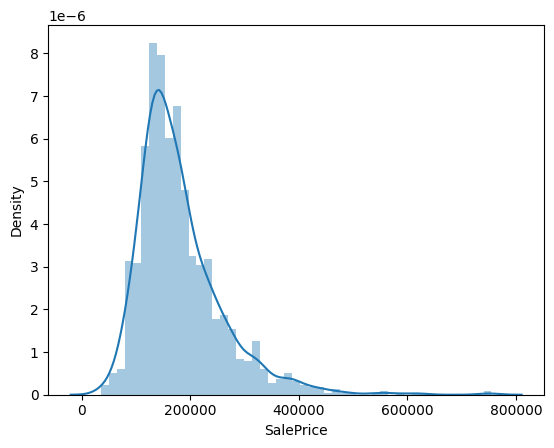

In [13]:
# Histograma
from seaborn import distplot
distplot(ames_housing["SalePrice"], hist=True)

<Axes: xlabel='OverallQual', ylabel='count'>

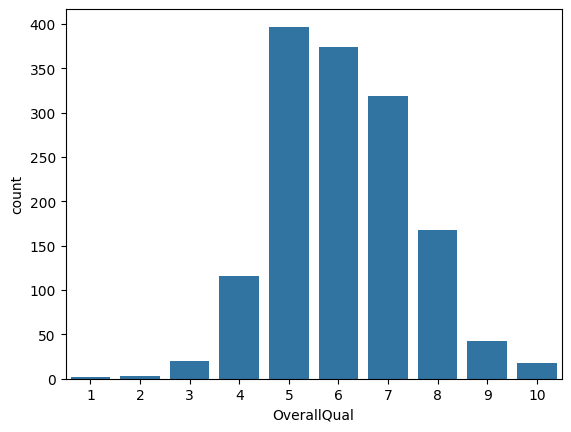

In [14]:
sns.countplot(x=ames_housing["OverallQual"])

/tmp/ipykernel_2040/907574774.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  distplot(ames_housing["GrLivArea"])


<Axes: xlabel='GrLivArea', ylabel='Density'>

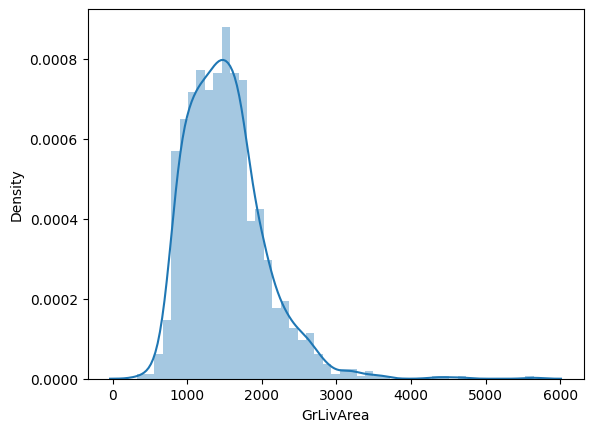

In [15]:
distplot(ames_housing["GrLivArea"])

/tmp/ipykernel_2040/510573693.py:13: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ames_housing[variable].dropna(), ax=axes[i][j])
/tmp/ipykernel_2040/510573693.py:13: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ames_housing[variable].dropna(), ax=axes[i][j])
/tmp/ipykernel_2040/510573693.py:1

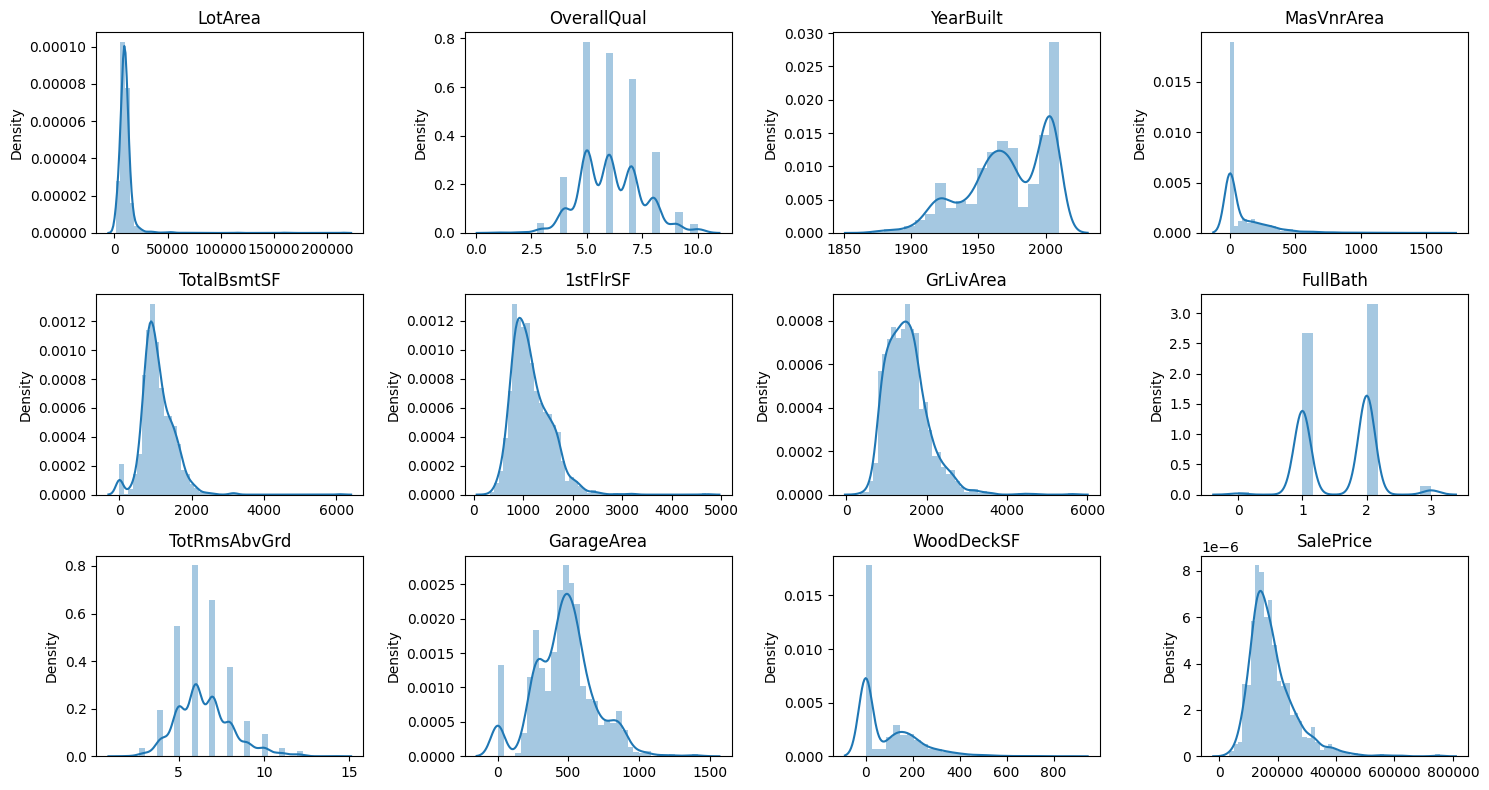

In [16]:
# Podemos usar un poco de código para visualizar más de una variable a la vez
variables = ['LotArea', 'OverallQual', 'YearBuilt', 'MasVnrArea',
            'TotalBsmtSF', '1stFlrSF', 'GrLivArea', 'FullBath',
            'TotRmsAbvGrd', 'GarageArea', 'WoodDeckSF', 'SalePrice']

columns = 4

fig, axes = plt.subplots(len(variables) // columns, columns, figsize=(15,8))

for current_idx, variable in enumerate(variables):
    i = current_idx // columns
    j = current_idx % columns
    sns.distplot(ames_housing[variable].dropna(), ax=axes[i][j])
    axes[i][j].set_title(variable)
    axes[i][j].set_xlabel("")

plt.tight_layout()

<Axes: ylabel='LotArea'>

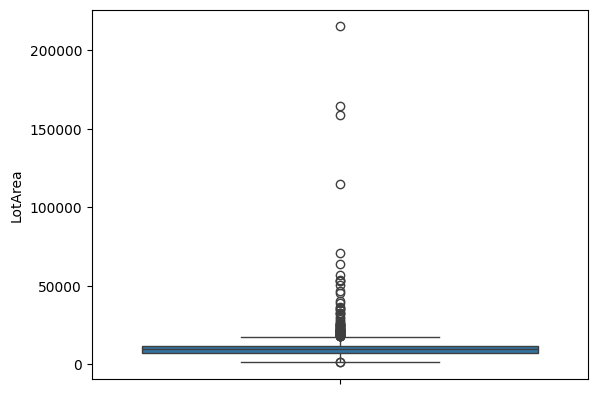

In [17]:
sns.boxplot(y=ames_housing["LotArea"])

### 💡 Conclusiones del EDA para el Preprocesamiento:
1. **Outliers y Asimetría:** Muchas variables numéricas (por ejemplo `LotArea`, `GrLivArea`, `MasVnrArea`) presentan distribuciones sesgadas con valores atípicos notables. Por ello, para imputar valores faltantes utilizaremos la **mediana** en lugar de la media (la mediana es un estimador robusto no afectado por extremos).
2. **Diferencias de Escala:** `LotArea` maneja valores en miles, mientras que `FullBath` o `OverallQual` son números pequeños entre 1 y 10. Estandarizaremos con `StandardScaler` para que todas las variables contribuyan en escalas comparables al modelo lineal.
3. **Valores Faltantes y Categorías:** Existen variables categóricas con nulos (como `Alley`, `GarageType`, etc.). Imputaremos con la moda (`most_frequent`) y codificaremos con `OneHotEncoder(handle_unknown="ignore")` para garantizar que si en inferencia aparece una categoría nueva, el sistema no se rompa.

## 4. División de Datos: Train / Test Split
> 🛡️ **Prevención Estricta de Fuga de Datos (Data Leakage):**
> Uno de los errores más graves en Machine Learning es calcular parámetros de preprocesamiento (como la media o mediana de una columna, el escalado, o las categorías del One-Hot) sobre **todo el dataset** antes de separarlo.
> Si hiciéramos eso, la información del conjunto de prueba se filtraría al entrenamiento.
>
> **Solución:** Realizamos la partición en Entrenamiento (80%) y Prueba (20%) inmediatamente después de separar la variable objetivo `SalePrice` y el identificador `Id`.

In [18]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Separación de características (X) y variable objetivo (y)
target_column = 'SalePrice'
X = ames_housing.drop(columns=[target_column, 'Id'], errors='ignore')
y = ames_housing[target_column]

# 2. train_test_split ANTES de cualquier transformación para evitar data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 3. Identificación programática de columnas numéricas y categóricas según el set de entrenamiento
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Features numéricos: {len(numeric_features)}")
print(f"Features categóricos: {len(categorical_features)}")

Features numéricos: 36
Features categóricos: 43


## 5. Definición de Transformers y Ensamblado con `ColumnTransformer`
A continuación, creamos dos pipelines de preprocesamiento especializados:

1. **`numeric_transformer` (Numéricas):**
   - **Paso 1 - Imputación:** `SimpleImputer(strategy="median")` para rellenar nulos numéricos de manera robusta.
   - **Paso 2 - Estandarización:** `StandardScaler()` para centrar en media 0 y varianza 1.

2. **`categorical_transformer` (Categóricas):**
   - **Paso 1 - Imputación:** `SimpleImputer(strategy="most_frequent")` para rellenar con la moda.
   - **Paso 2 - Codificación:** `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` para crear variables dummies binarias sin riesgo de fallar ante categorías desconocidas.

Luego, integramos ambos en un objeto **`ColumnTransformer`**, asignando cada pipeline a su conjunto de columnas correspondiente y descartando columnas residuales no deseadas (`remainder="drop"`).

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Pipeline de preprocesamiento para variables numéricas:
# Imputación por mediana (robusta a outliers observados en el EDA) y estandarización
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline de preprocesamiento para variables categóricas:
# Imputación por el valor más frecuente y One-Hot Encoding ignorando categorías no vistas en inferencia
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Ensamblado del preprocesador mediante ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'  # Descarta cualquier columna no especificada
)

## 6. Ensamblaje del Pipeline Final (Preprocesamiento + Modelo Predictivo)
Encapsulamos el preprocesador y el estimador de Machine Learning en un único `Pipeline` global.

Como estimador utilizamos una regresión lineal regularizada **`Ridge`** (alpha = 1.0), adecuada para problemas tabulares continuos donde el One-Hot genera múltiples columnas y se desea prevenir el sobreajuste (overfitting).

In [20]:
from sklearn.linear_model import Ridge

# Pipeline end-to-end: Preprocesamiento + Modelo
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0, random_state=42))
])

## 7. Entrenamiento y Evaluación del Modelo
Al ejecutar `model_pipeline.fit(X_train, y_train)` ocurren dos cosas de manera ordenada y segura:
1. El `preprocessor` ejecuta `fit_transform` calculando medianas, escalas y categorías **únicamente** con `X_train`.
2. El estimador `Ridge` se entrena con esa matriz ya transformada.

Luego, al predecir con `model_pipeline.predict(X_test)`, el pipeline aplica automáticamente el método `.transform()` sin recalcular ningún parámetro, eliminando cualquier fuga de datos.

Evaluamos el desempeño con tres métricas fundamentales:
- **R² (Coeficiente de determinación):** Proporción de la varianza explicada por el modelo.
- **MAE (Error Absoluto Medio):** Error promedio en dólares.
- **RMSE (Raíz del Error Cuadrático Medio):** Magnitud promedio del error penalizando desvíos grandes.

In [21]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Entrenamiento del pipeline completo (ajusta transformadores y estimador sólo con train)
model_pipeline.fit(X_train, y_train)

# Inferencia sobre datos no vistos
y_pred = model_pipeline.predict(X_test)

# Reporte de métricas de desempeño
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- Reporte de Métricas en Test ---")
print(f"R² Score: {r2:.4f}")
print(f"MAE:      ${mae:,.2f}")
print(f"RMSE:     ${rmse:,.2f}")

--- Reporte de Métricas en Test ---
R² Score: 0.8844
MAE:      $19,096.24
RMSE:     $29,777.46


### 📊 Interpretación de Resultados:
- **R² ≈ 0.8844:** El modelo explica más del 88% de la variabilidad del precio de las viviendas en datos nunca antes vistos.
- **MAE ≈ $19,096 USD:** En promedio, la predicción difiere en ~19 mil dólares del precio real de venta, un valor competitivo considerando que las propiedades rondan los $180,000.
- **RMSE ≈ $29,777 USD:** Proporciona un límite de error penalizando las predicciones con mayor desvío.

## 8. Persistencia del Pipeline con `joblib` y Prueba de Inferencia
Para cerrar el ciclo de vida del modelo de forma profesional, guardamos el pipeline entrenado en un archivo binario `.joblib`.

Posteriormente, simulamos un entorno de producción donde cargamos el archivo y le pasamos un DataFrame **crudo** (con columnas originales sin preprocesar) para confirmar que el método `.predict()` responde inmediatamente y sin errores de formato.

In [22]:
import joblib

# Guardar el pipeline entrenado en disco
model_filename = 'ames_housing_pipeline.joblib'
joblib.dump(model_pipeline, model_filename)
print(f"Pipeline exportado exitosamente en: {model_filename}")

# Verificación de carga e inferencia directa sobre datos crudos
loaded_pipeline = joblib.load(model_filename)
sample_prediction = loaded_pipeline.predict(X_test.iloc[:5])
print("Predicciones de prueba del pipeline cargado:", np.round(sample_prediction, 2))

Pipeline exportado exitosamente en: ames_housing_pipeline.joblib
Predicciones de prueba del pipeline cargado: [156995.05 341812.36  92162.69 178291.09 326647.14]


## 9. Respuestas y Justificaciones a la Rúbrica de la Entrega

| Criterio Evaluado | Estado | Justificación Técnica |
| :--- | :---: | :--- |
| **1. Archivo README.md con descripción del dataset** | ✅ Cumplido | El repositorio cuenta con un archivo `README.md` completo que documenta el dataset Ames Housing, la arquitectura del pipeline, métricas y guía de uso. |
| **2. Uso de clase `Pipeline` con ≥ 2 pasos** | ✅ Cumplido | Se construyeron pipelines dedicados: `numeric_transformer` (imputación + escalado) y `categorical_transformer` (imputación + codificación), además del pipeline global. |
| **3. `ColumnTransformer` para numéricas y categóricas** | ✅ Cumplido | Se utilizó `ColumnTransformer` mapeando 36 variables numéricas y 43 variables categóricas con estrategias de preprocesamiento diferenciadas. |
| **4. Train/Test split antes del ajuste (No Data Leakage)** | ✅ Cumplido | `train_test_split` (80/20) se realizó de forma previa a cualquier cálculo de media, mediana o categorías (`fit`), protegiendo la validez del set de prueba. |
| **5. Pipeline funcional con `.predict()` sobre datos nuevos** | ✅ Cumplido | El pipeline completo fue entrenado, guardado con `joblib`, recargado y probado satisfactoriamente con filas crudas de prueba sin errores de formato. |